**Run the cell below first.** Its code is collapsed (click the `...` to
expand it) because it is one-time setup, not part of the lesson -- but it
still has to run once, before anything else in this notebook, or later
cells will fail with `NameError`. Click it, then press Shift+Enter (or the
Run button), and continue through the notebook in order from there.


In [ ]:
import sys
import random
import warnings

warnings.filterwarnings("ignore", message=r"The (width|height|x|y) parameter as float was deprecated")

# This notebook's pinned browser kernel's own threadpoolctl (imported
# internally by scikit-learn, not by this notebook) emits the same
# upstream RuntimeWarning as every other notebook in this course that fits
# a scikit-learn model under Pyodide, reproduced live in this exact browser
# build, firing from threadpoolctl's own Pyodide shared-library
# introspection whenever a model is fit, including this notebook's
# one-split cell -- same narrow, message-and-category-scoped filter,
# applied consistently rather than reinventing it per notebook.
warnings.filterwarnings(
    "ignore",
    message=r"JsProxy\.as_object_map\(\) is deprecated",
    category=RuntimeWarning,
)

if sys.platform == "emscripten":
    # Running in the browser (JupyterLite). ipywidgets has no prebuilt
    # Pyodide package, unlike numpy/pandas/scikit-learn/matplotlib
    # (preloaded by the JupyterLite build, see book/lite/overrides.json),
    # so it is fetched here instead of by a student-run install cell.
    # Local Jupyter and Colab already have ipywidgets installed.
    import micropip

    await micropip.install(["ipywidgets"])

import numpy as np
import pandas as pd
import ipywidgets as widgets
from IPython.display import display, HTML

_ABIDE_LITE_FEATURES = [
    'fsCT_L_1_ROI', 'fsCT_R_1_ROI', 'fsCT_L_10d_ROI', 'fsCT_R_10d_ROI',
    'fsCT_L_10pp_ROI', 'fsCT_R_10pp_ROI', 'fsCT_L_10r_ROI', 'fsCT_R_10r_ROI',
    'fsCT_L_10v_ROI', 'fsCT_R_10v_ROI', 'fsCT_L_11l_ROI', 'fsCT_R_11l_ROI',
    'fsCT_L_13l_ROI', 'fsCT_R_13l_ROI', 'fsCT_L_2_ROI', 'fsCT_R_2_ROI',
    'fsCT_L_23c_ROI', 'fsCT_R_23c_ROI', 'fsCT_L_23d_ROI', 'fsCT_R_23d_ROI',
    'fsCT_L_24dd_ROI', 'fsCT_R_24dd_ROI', 'fsCT_L_24dv_ROI', 'fsCT_R_24dv_ROI',
    'fsCT_L_25_ROI', 'fsCT_R_25_ROI', 'fsCT_L_31a_ROI', 'fsCT_R_31a_ROI',
    'fsCT_L_31pd_ROI', 'fsCT_R_31pd_ROI', 'fsCT_L_31pv_ROI', 'fsCT_R_31pv_ROI',
    'fsCT_L_33pr_ROI', 'fsCT_R_33pr_ROI', 'fsCT_L_3a_ROI', 'fsCT_R_3a_ROI',
    'fsCT_L_3b_ROI', 'fsCT_R_3b_ROI', 'fsCT_L_4_ROI', 'fsCT_R_4_ROI',
    'fsCT_L_43_ROI', 'fsCT_R_43_ROI', 'fsCT_L_44_ROI', 'fsCT_R_44_ROI',
    'fsCT_L_45_ROI', 'fsCT_R_45_ROI', 'fsCT_L_46_ROI', 'fsCT_R_46_ROI',
    'fsCT_L_47l_ROI', 'fsCT_R_47l_ROI', 'fsCT_L_47m_ROI', 'fsCT_R_47m_ROI',
    'fsCT_L_47s_ROI', 'fsCT_R_47s_ROI', 'fsCT_L_5L_ROI', 'fsCT_R_5R_ROI',
    'fsCT_L_52_ROI', 'fsCT_R_52_ROI', 'fsCT_L_55b_ROI', 'fsCT_R_55b_ROI',
    'fsCT_L_5m_ROI', 'fsCT_R_5m_ROI', 'fsCT_L_5mv_ROI', 'fsCT_R_5mv_ROI',
    'fsCT_L_6a_ROI', 'fsCT_R_6a_ROI', 'fsCT_L_6d_ROI', 'fsCT_R_6d_ROI',
    'fsCT_L_6ma_ROI', 'fsCT_R_6ma_ROI', 'fsCT_L_6mp_ROI', 'fsCT_R_6mp_ROI',
    'fsCT_L_6r_ROI', 'fsCT_R_6r_ROI', 'fsCT_L_6v_ROI', 'fsCT_R_6v_ROI',
    'fsCT_L_7AL_ROI', 'fsCT_R_7AL_ROI', 'fsCT_L_7Am_ROI', 'fsCT_R_7Am_ROI',
    'fsCT_L_7PC_ROI', 'fsCT_R_7PC_ROI', 'fsCT_L_7PL_ROI', 'fsCT_R_7PL_ROI',
    'fsCT_L_7Pm_ROI', 'fsCT_R_7Pm_ROI', 'fsCT_L_7m_ROI', 'fsCT_R_7m_ROI',
    'fsCT_L_8Ad_ROI', 'fsCT_R_8Ad_ROI', 'fsCT_L_8Av_ROI', 'fsCT_R_8Av_ROI',
    'fsCT_L_8BL_ROI', 'fsCT_R_8BL_ROI', 'fsCT_L_8BM_ROI', 'fsCT_R_8BM_ROI',
    'fsCT_L_8C_ROI', 'fsCT_R_8C_ROI', 'fsCT_L_9-46d_ROI', 'fsCT_R_9-46d_ROI',
    'fsCT_L_9a_ROI', 'fsCT_R_9a_ROI', 'fsCT_L_9m_ROI', 'fsCT_R_9m_ROI',
    'fsCT_L_9p_ROI', 'fsCT_R_9p_ROI', 'fsCT_L_A1_ROI', 'fsCT_R_A1_ROI',
    'fsCT_L_A4_ROI', 'fsCT_R_A4_ROI', 'fsCT_L_A5_ROI', 'fsCT_R_A5_ROI',
    'fsCT_L_AAIC_ROI', 'fsCT_R_AAIC_ROI', 'fsCT_L_AIP_ROI', 'fsCT_R_AIP_ROI',
    'fsCT_L_AVI_ROI', 'fsCT_R_AVI_ROI', 'fsCT_L_DVT_ROI', 'fsCT_R_DVT_ROI',
    'fsCT_L_EC_ROI', 'fsCT_R_EC_ROI', 'fsCT_L_FEF_ROI', 'fsCT_R_FEF_ROI',
    'fsCT_L_FFC_ROI', 'fsCT_R_FFC_ROI', 'fsCT_L_FOP1_ROI', 'fsCT_R_FOP1_ROI',
    'fsCT_L_FOP2_ROI', 'fsCT_R_FOP2_ROI', 'fsCT_L_FOP3_ROI', 'fsCT_R_FOP3_ROI',
    'fsCT_L_FOP4_ROI', 'fsCT_R_FOP4_ROI', 'fsCT_L_FOP5_ROI', 'fsCT_R_FOP5_ROI',
    'fsCT_L_FST_ROI', 'fsCT_R_FST_ROI', 'fsCT_L_H_ROI', 'fsCT_R_H_ROI',
    'fsCT_L_IFJa_ROI', 'fsCT_R_IFJa_ROI', 'fsCT_L_IFJp_ROI', 'fsCT_R_IFJp_ROI',
    'fsCT_L_IFSa_ROI', 'fsCT_R_IFSa_ROI', 'fsCT_L_IFSp_ROI', 'fsCT_R_IFSp_ROI',
    'fsCT_L_IP0_ROI', 'fsCT_R_IP0_ROI', 'fsCT_L_IP1_ROI', 'fsCT_R_IP1_ROI',
    'fsCT_L_IP2_ROI', 'fsCT_R_IP2_ROI', 'fsCT_L_IPS1_ROI', 'fsCT_R_IPS1_ROI',
    'fsCT_L_Ig_ROI', 'fsCT_R_Ig_ROI', 'fsCT_L_LBelt_ROI', 'fsCT_R_LBelt_ROI',
    'fsCT_L_LIPd_ROI', 'fsCT_R_LIPd_ROI', 'fsCT_L_LIPv_ROI', 'fsCT_R_LIPv_ROI',
    'fsCT_L_LO1_ROI', 'fsCT_R_LO1_ROI', 'fsCT_L_LO2_ROI', 'fsCT_R_LO2_ROI',
    'fsCT_L_LO3_ROI', 'fsCT_R_LO3_ROI', 'fsCT_L_MBelt_ROI', 'fsCT_R_MBelt_ROI',
    'fsCT_L_MI_ROI', 'fsCT_R_MI_ROI', 'fsCT_L_MIP_ROI', 'fsCT_R_MIP_ROI',
    'fsCT_L_MST_ROI', 'fsCT_R_MST_ROI', 'fsCT_L_MT_ROI', 'fsCT_R_MT_ROI',
    'fsCT_L_OFC_ROI', 'fsCT_R_OFC_ROI', 'fsCT_L_OP1_ROI', 'fsCT_R_OP1_ROI',
    'fsCT_L_OP2-3_ROI', 'fsCT_R_OP2-3_ROI', 'fsCT_L_OP4_ROI', 'fsCT_R_OP4_ROI',
    'fsCT_L_PBelt_ROI', 'fsCT_R_PBelt_ROI', 'fsCT_L_PCV_ROI', 'fsCT_R_PCV_ROI',
    'fsCT_L_PEF_ROI', 'fsCT_R_PEF_ROI', 'fsCT_L_PF_ROI', 'fsCT_R_PF_ROI',
    'fsCT_L_PFcm_ROI', 'fsCT_R_PFcm_ROI', 'fsCT_L_PFm_ROI', 'fsCT_R_PFm_ROI',
    'fsCT_L_PFop_ROI', 'fsCT_R_PFop_ROI', 'fsCT_L_PFt_ROI', 'fsCT_R_PFt_ROI',
    'fsCT_L_PGi_ROI', 'fsCT_R_PGi_ROI', 'fsCT_L_PGp_ROI', 'fsCT_R_PGp_ROI',
    'fsCT_L_PGs_ROI', 'fsCT_R_PGs_ROI', 'fsCT_L_PH_ROI', 'fsCT_R_PH_ROI',
    'fsCT_L_PHA1_ROI', 'fsCT_R_PHA1_ROI', 'fsCT_L_PHA2_ROI', 'fsCT_R_PHA2_ROI',
    'fsCT_L_PHA3_ROI', 'fsCT_R_PHA3_ROI', 'fsCT_L_PHT_ROI', 'fsCT_R_PHT_ROI',
    'fsCT_L_PI_ROI', 'fsCT_R_PI_ROI', 'fsCT_L_PIT_ROI', 'fsCT_R_PIT_ROI',
    'fsCT_L_POS1_ROI', 'fsCT_R_POS1_ROI', 'fsCT_L_POS2_ROI', 'fsCT_R_POS2_ROI',
    'fsCT_L_PSL_ROI', 'fsCT_R_PSL_ROI', 'fsCT_L_PeEc_ROI', 'fsCT_R_PeEc_ROI',
    'fsCT_L_Pir_ROI', 'fsCT_R_Pir_ROI', 'fsCT_L_PoI1_ROI', 'fsCT_R_PoI1_ROI',
    'fsCT_L_PoI2_ROI', 'fsCT_R_PoI2_ROI', 'fsCT_L_PreS_ROI', 'fsCT_R_PreS_ROI',
    'fsCT_L_ProS_ROI', 'fsCT_R_ProS_ROI', 'fsCT_L_RI_ROI', 'fsCT_R_RI_ROI',
    'fsCT_L_RSC_ROI', 'fsCT_R_RSC_ROI', 'fsCT_L_SCEF_ROI', 'fsCT_R_SCEF_ROI',
    'fsCT_L_SFL_ROI', 'fsCT_R_SFL_ROI', 'fsCT_L_STGa_ROI', 'fsCT_R_STGa_ROI',
    'fsCT_L_STSda_ROI', 'fsCT_R_STSda_ROI', 'fsCT_L_STSdp_ROI', 'fsCT_R_STSdp_ROI',
    'fsCT_L_STSva_ROI', 'fsCT_R_STSva_ROI', 'fsCT_L_STSvp_ROI', 'fsCT_R_STSvp_ROI',
    'fsCT_L_STV_ROI', 'fsCT_R_STV_ROI', 'fsCT_L_TA2_ROI', 'fsCT_R_TA2_ROI',
    'fsCT_L_TE1a_ROI', 'fsCT_R_TE1a_ROI', 'fsCT_L_TE1m_ROI', 'fsCT_R_TE1m_ROI',
    'fsCT_L_TE1p_ROI', 'fsCT_R_TE1p_ROI', 'fsCT_L_TE2a_ROI', 'fsCT_R_TE2a_ROI',
    'fsCT_L_TE2p_ROI', 'fsCT_R_TE2p_ROI', 'fsCT_L_TF_ROI', 'fsCT_R_TF_ROI',
    'fsCT_L_TGd_ROI', 'fsCT_R_TGd_ROI', 'fsCT_L_TGv_ROI', 'fsCT_R_TGv_ROI',
    'fsCT_L_TPOJ1_ROI', 'fsCT_R_TPOJ1_ROI', 'fsCT_L_TPOJ2_ROI', 'fsCT_R_TPOJ2_ROI',
    'fsCT_L_TPOJ3_ROI', 'fsCT_R_TPOJ3_ROI', 'fsCT_L_V1_ROI', 'fsCT_R_V1_ROI',
    'fsCT_L_V2_ROI', 'fsCT_R_V2_ROI', 'fsCT_L_V3_ROI', 'fsCT_R_V3_ROI',
    'fsCT_L_V3A_ROI', 'fsCT_R_V3A_ROI', 'fsCT_L_V3B_ROI', 'fsCT_R_V3B_ROI',
    'fsCT_L_V3CD_ROI', 'fsCT_R_V3CD_ROI', 'fsCT_L_V4_ROI', 'fsCT_R_V4_ROI',
    'fsCT_L_V4t_ROI', 'fsCT_R_V4t_ROI', 'fsCT_L_V6_ROI', 'fsCT_R_V6_ROI',
    'fsCT_L_V6A_ROI', 'fsCT_R_V6A_ROI', 'fsCT_L_V7_ROI', 'fsCT_R_V7_ROI',
    'fsCT_L_V8_ROI', 'fsCT_R_V8_ROI', 'fsCT_L_VIP_ROI', 'fsCT_R_VIP_ROI',
    'fsCT_L_VMV1_ROI', 'fsCT_R_VMV1_ROI', 'fsCT_L_VMV2_ROI', 'fsCT_R_VMV2_ROI',
    'fsCT_L_VMV3_ROI', 'fsCT_R_VMV3_ROI', 'fsCT_L_VVC_ROI', 'fsCT_R_VVC_ROI',
    'fsCT_L_a10p_ROI', 'fsCT_R_a10p_ROI', 'fsCT_L_a24_ROI', 'fsCT_R_a24_ROI',
    'fsCT_L_a24pr_ROI', 'fsCT_R_a24pr_ROI', 'fsCT_L_a32pr_ROI', 'fsCT_R_a32pr_ROI',
    'fsCT_L_a47r_ROI', 'fsCT_R_a47r_ROI', 'fsCT_L_a9-46v_ROI', 'fsCT_R_a9-46v_ROI',
    'fsCT_L_d23ab_ROI', 'fsCT_R_d23ab_ROI', 'fsCT_L_d32_ROI', 'fsCT_R_d32_ROI',
    'fsCT_L_i6-8_ROI', 'fsCT_R_i6-8_ROI', 'fsCT_L_p10p_ROI', 'fsCT_R_p10p_ROI',
    'fsCT_L_p24_ROI', 'fsCT_R_p24_ROI', 'fsCT_L_p24pr_ROI', 'fsCT_R_p24pr_ROI',
    'fsCT_L_p32_ROI', 'fsCT_R_p32_ROI', 'fsCT_L_p32pr_ROI', 'fsCT_R_p32pr_ROI',
    'fsCT_L_p47r_ROI', 'fsCT_R_p47r_ROI', 'fsCT_L_p9-46v_ROI', 'fsCT_R_p9-46v_ROI',
    'fsCT_L_pOFC_ROI', 'fsCT_R_pOFC_ROI', 'fsCT_L_s32_ROI', 'fsCT_R_s32_ROI',
    'fsCT_L_s6-8_ROI', 'fsCT_R_s6-8_ROI', 'fsCT_L_v23ab_ROI', 'fsCT_R_v23ab_ROI',
]


def load_abide_age_brain_table():
    """Return the age/brain table: 360 cortical-thickness predictors, age,
    and group (autism/control, used only to reproduce the established
    train/test split -- never a model feature).

    Tries the small same-origin file this notebook ships next to first
    (JupyterLite, or a full local checkout); falls back to the same pinned,
    checksummed public source this course already uses elsewhere (a bare
    downloaded .ipynb, or Colab, neither of which has the sibling data
    file). Both paths return identically shaped, identically ordered
    columns, so the rest of this notebook never needs to know which one ran.
    """
    from pathlib import Path

    local_path = Path("data/abide_age_brain.csv")
    if local_path.exists():
        table = pd.read_csv(local_path)
    else:
        url = (
            "https://raw.githubusercontent.com/neurohackademy/nh2020-curriculum/"
            "e4eed3c4daa7f40b0ba931182a8c7e5e691dba6b/"
            "tu-machine-learning-yarkoni/data/abide2.tsv"
        )
        table = pd.read_csv(url, sep="\t")
    table = table.dropna(subset=["age"])
    return table[_ABIDE_LITE_FEATURES + ["age", "group"]].reset_index(drop=True)


_QUESTION_CSS = """
<style>
.checked-question .widget-checkbox { width: 100% !important; height: auto !important; }
.checked-question .widget-label-basic {
    width: 100% !important;
    white-space: normal !important;
    overflow: visible !important;
    text-overflow: unset !important;
    height: auto !important;
}
.checked-question .widget-radio-box { width: 100% !important; }
.checked-question .widget-radio-box label {
    width: 100% !important;
    max-width: 100% !important;
    white-space: normal !important;
    height: auto !important;
    box-sizing: border-box;
    padding: 3px 0;
    line-height: 1.3;
}
</style>
"""


def _question_style_widget():
    return widgets.HTML(_QUESTION_CSS, layout=widgets.Layout(height="0px", margin="0px", padding="0px"))


def make_single_choice_question(prompt, options, correct_index, feedback_correct="Correct.", feedback_incorrect="Not quite -- try again."):
    """A compact single-choice checked question. Returns a widget to display()."""
    radio = widgets.RadioButtons(options=list(options), description="", layout=widgets.Layout(width="100%"))
    button = widgets.Button(description="Check answer", button_style="primary")
    feedback = widgets.Output()

    def _on_click(_button):
        with feedback:
            feedback.clear_output(wait=True)
            print(feedback_correct if radio.index == correct_index else feedback_incorrect)

    button.on_click(_on_click)
    box = widgets.VBox(
        [_question_style_widget(), widgets.HTML(f"<b>{prompt}</b>"), radio, button, feedback],
        layout=widgets.Layout(width="100%"),
    )
    box.add_class("checked-question")
    return box


def make_multi_choice_question(prompt, options, correct_indices, feedback_correct="Correct.", feedback_incorrect="Not quite -- try again."):
    """A compact multiple-selection checked question. Returns a widget to display()."""
    correct = set(correct_indices)
    boxes = [
        widgets.Checkbox(value=False, description=opt, indent=False, layout=widgets.Layout(width="100%"))
        for opt in options
    ]
    button = widgets.Button(description="Check answer", button_style="primary")
    feedback = widgets.Output()

    def _on_click(_button):
        selected = {i for i, cb in enumerate(boxes) if cb.value}
        with feedback:
            feedback.clear_output(wait=True)
            print(feedback_correct if selected == correct else feedback_incorrect)

    button.on_click(_on_click)
    box = widgets.VBox(
        [_question_style_widget(), widgets.HTML(f"<b>{prompt}</b>")] + boxes + [button, feedback],
        layout=widgets.Layout(width="100%"),
    )
    box.add_class("checked-question")
    return box


# Question content lives here, not in the visible cell that displays it: a
# visible call like show_question("q-inner-loop-data") never prints or displays
# a correct_index/correct_indices value. This is visual concealment, not
# secure assessment: the hidden cell is fully expandable, and a downloaded,
# fully offline, editable notebook must contain enough information to check an
# answer locally, so a technically curious student can always recover it from
# source or the running kernel.
_QUESTIONS = {
    "q-single-split-vs-cv-stability": dict(
        kind="single",
        shuffle_seed=113,
        prompt=(
            "At a small sample size (for example, 150 or 250 participants), why can "
            "changing only the random seed swing the single-split test R^2 by a "
            "large amount, while the 5-fold cross-validation mean tends to move "
            "less?"
        ),
        options=[
            "The single split evaluates on only one held-out subset of participants, so which few participants land there matters a lot; cross-validation averages over several different held-out subsets, so unusually easy or hard subsets tend to cancel out.",
            "Cross-validation always uses more participants in total than a single split.",
            "KNN itself becomes a different algorithm when cross-validated.",
        ],
        correct_index=0,
        feedback_correct="Correct: averaging several held-out subsets, rather than reporting just one, is what makes cross-validation's summary more stable than a single split's.",
    ),
    "q-inner-loop-data": dict(
        kind="single",
        shuffle_seed=114,
        prompt=(
            "Inside the pipeline above, which participants does the inner "
            "GridSearchCV use to choose k for a given outer fold?"
        ),
        options=[
            "Only that outer fold's training data -- the outer fold's own test data is never used to select k.",
            "All 1004 participants, including the current outer fold's test data.",
            "Only the current outer fold's test data.",
        ],
        correct_index=0,
        feedback_correct="Correct: the inner loop selects k using only the outer fold's training data, so the outer test fold stays untouched by the tuning decision.",
    ),
    "q-outer-test-mse-meaning": dict(
        kind="single",
        shuffle_seed=115,
        prompt=(
            "What does the mean outer-test MSE (averaged across the 5 outer folds) "
            "actually estimate?"
        ),
        options=[
            "The performance of the complete tuning procedure -- choosing k with inner cross-validation, then evaluating that choice on data the inner loop never saw -- not the performance of one single, fixed k.",
            "The performance of whichever k happened to score best on the inner cross-validation.",
            "The performance of a KNN model with k chosen by looking at all the outer-test folds at once.",
        ],
        correct_index=0,
        feedback_correct="Correct: nested cross-validation's outer score estimates the tuning procedure's performance, which is what you would actually get by repeating this whole inner-selection process on new data.",
    ),
}


def show_question(question_id):
    q = _QUESTIONS[question_id]
    order = list(range(len(q["options"])))
    random.Random(q["shuffle_seed"]).shuffle(order)
    shuffled_options = [q["options"][i] for i in order]
    if q["kind"] == "single":
        widget = make_single_choice_question(
            q["prompt"],
            shuffled_options,
            order.index(q["correct_index"]),
            q.get("feedback_correct", "Correct."),
            q.get("feedback_incorrect", "Not quite -- try again."),
        )
    else:
        shuffled_correct = {order.index(i) for i in q["correct_indices"]}
        widget = make_multi_choice_question(
            q["prompt"],
            shuffled_options,
            shuffled_correct,
            q.get("feedback_correct", "Correct."),
            q.get("feedback_incorrect", "Not quite -- try again."),
        )
    display(widget)


# Exercise 4: Validation and Cross-Validation


## What this notebook covers

This is Exercise 4 of *Machine Learning for Neuroscience*. It reuses
Exercise 2's ABIDE-II age-prediction task and its fixed KNN predictor set
unchanged, and compares one train/test split with cross-validation. The
predictors were already fixed before this lesson -- nothing here selects,
adds, or removes a feature; feature selection is Exercise 5's topic.

In this notebook you will:

1. reuse Exercise 2's ABIDE age-prediction data and its fixed KNN predictors;
2. see one train/test split and its MSE, computed with the fixed `k` used
   throughout this notebook;
3. write code that evaluates the same fixed model with 5-fold cross-validation;
4. compare a single split with cross-validation across several sample sizes;
5. complete a guided nested cross-validation pipeline that tunes `k` and
   evaluates the tuning procedure honestly.

Written-answer cells (bold questions in a blockquote) are ordinary Markdown:
double-click one to edit it, type your answer, then press Shift+Enter to
render it back. Your answer is saved with the rest of this notebook,
including in **Download my notebook**.

**Prerequisites:** Exercise 2's regression and KNN material; comfort with
`pandas`, `numpy`, and the scikit-learn `fit` / `predict` / `Pipeline` pattern.


## 1. Data and setup


**Target:** age (a continuous measurement, in years). **Predictors:** the
same 360 bilateral cortical-thickness (`fsCT_`) columns Exercise 2 used,
fixed before this lesson. **Metric:** mean squared error (MSE) -- the same
regression metric Exercise 2 used, since the target here is continuous, not
a class label.


In [ ]:
# Load the approved ABIDE-II age-prediction table: the same 1004-participant,
# 360-feature cortical-thickness table Exercise 2 uses.
try:
    df = load_abide_age_brain_table()
except NameError as exc:
    raise RuntimeError(
        "load_abide_age_brain_table is not defined yet. Run this "
        "notebook's first code cell (collapsed, at the very top, under "
        "'Run the cell below first') before this one, then run this cell again."
    ) from exc

FEATURES = [c for c in df.columns if c.startswith("fsCT_")]
X = df[FEATURES].to_numpy(float)
y = df["age"].to_numpy(float)
groups = df["group"].to_numpy()  # 1 = autism, 2 = control; stratification key only, never a predictor

print(f"{len(df)} participants, {len(FEATURES)} brain predictors, target = age")
df[FEATURES[:3] + ["age"]].head()


In [ ]:
from sklearn.model_selection import train_test_split, KFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.metrics import mean_squared_error, r2_score


The train/test split below reuses Exercise 2's exact fixed arguments, so
the two partitions here are identical to Exercise 2's own.


In [ ]:
X_train, X_test, y_train, y_test, groups_train, groups_test = train_test_split(
    X, y, groups, test_size=0.25, random_state=42, stratify=groups
)
print(f"n_train = {len(y_train)}   n_test = {len(y_test)}   n_features = {X.shape[1]}")


A reminder, already established in Exercise 2: KNN predicts a participant's
age by averaging the `k` training participants whose predictors are closest
to theirs, so scaling matters -- an unscaled predictor with a large numeric
range would dominate that distance just because of its units. A
scikit-learn `Pipeline` keeps `StandardScaler` bundled with the model, fit
on training data only and refit separately inside every fold below.


## 2. One Train/Test Split


The cell below fits one KNN model, with `k = 20` (the same fixed
value used in Exercise 2's own worked example), on the training partition
above and evaluates it once on the held-out test partition.


In [ ]:
K_EXAMPLE = 20  # the value used throughout this notebook, from Exercise 2's own worked example

one_split_model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=K_EXAMPLE))
one_split_model.fit(X_train, y_train)
one_split_pred = one_split_model.predict(X_test)
one_split_mse = mean_squared_error(y_test, one_split_pred)
one_split_r2 = r2_score(y_test, one_split_pred)
print(f"one split: test MSE = {one_split_mse:.1f}   test R^2 = {one_split_r2:.3f}")


> This single number is an honest estimate of performance on participants
> the model never trained on -- but it depends on exactly which
> participants happened to land in the training set and which landed in the
> test set. A different split could give a somewhat different MSE for the
> exact same model and data. Section 4 lets you see this directly.


## 3. Evaluate the Same Model with Cross-Validation


**Cross-validation** partitions the data into several folds, fits the model
on all-but-one fold, evaluates it on the held-out fold, and repeats until
every fold has served as the held-out one once -- giving several performance
estimates from the same data instead of one.

Write code that runs 5-fold cross-validation of the **same fixed model**
(`k = 20`, the same value as Section 2 -- this activity evaluates
one model, it does not choose `k`) on the **full** `X`/`y` (not just the
training partition above), and prints each fold's MSE and the mean MSE.

Hints:
- `KFold(n_splits=5, shuffle=True, random_state=0)` gives 5 reproducible
  folds; scikit-learn's `cross_validate(..., scoring="neg_mean_squared_error")`
  (or an equivalent loop over `kf.split(X)`) fits and scores each one. Put
  `StandardScaler` in the same `Pipeline`/`make_pipeline` as the model so it
  is refit separately inside every fold -- never fit once on all the data.
- scikit-learn's cross-validation scorers report **negative** MSE (so that,
  like every other scorer, a higher score is always better); negate it back
  to ordinary (positive) MSE before printing.


In [ ]:
cv_pipe = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=K_EXAMPLE))
cv_folds = KFold(n_splits=5, shuffle=True, random_state=0)
cv_scores = cross_validate(cv_pipe, X, y, cv=cv_folds, scoring=("neg_mean_squared_error", "r2"))

# scikit-learn reports NEGATIVE MSE; negate it back to ordinary (positive) MSE.
cv_fold_mse = -cv_scores["test_neg_mean_squared_error"]
cv_fold_r2 = cv_scores["test_r2"]
cv_mean_mse = cv_fold_mse.mean()
cv_mean_r2 = cv_fold_r2.mean()
for i, (fold_mse, fold_r2) in enumerate(zip(cv_fold_mse, cv_fold_r2), start=1):
    print(f"fold {i}: MSE = {fold_mse:.1f}   R^2 = {fold_r2:.3f}")
print(f"mean MSE = {cv_mean_mse:.1f}   (sd {cv_fold_mse.std():.1f})")
print(f"mean R^2 = {cv_mean_r2:.3f}")


In [ ]:
# Run this to check your cross-validation results.
EXPECTED_CV_MEAN_MSE = 33.8121
MSE_TOLERANCE = 8.0  # generous: absorbs reasonable, equally valid fold orderings

if "cv_fold_mse" in globals() and "cv_mean_mse" in globals():
    import numpy as np
    fold_mses = np.asarray(cv_fold_mse, dtype=float)
    if len(fold_mses) != 5:
        print(f"Not quite: found {len(fold_mses)} fold MSE values; 5-fold cross-validation should give exactly 5.")
    elif not np.isfinite(fold_mses).all() or (fold_mses < 0).any():
        print("Not quite: every fold MSE should be a finite, non-negative number.")
    elif abs(cv_mean_mse - EXPECTED_CV_MEAN_MSE) <= MSE_TOLERANCE:
        print(f"Looks good: 5 fold MSEs, mean MSE = {cv_mean_mse:.1f} (expected ~{EXPECTED_CV_MEAN_MSE:.1f}).")
    else:
        print(
            f"Your mean MSE ({cv_mean_mse:.1f}) differs from the expected result "
            f"(~{EXPECTED_CV_MEAN_MSE:.1f}). That does not automatically mean something "
            "is wrong -- check that you used k=K_EXAMPLE, the full X/y, and "
            "KFold(n_splits=5, shuffle=True, random_state=0) before assuming this is an error."
        )
else:
    print("Not complete yet: define cv_fold_mse and cv_mean_mse above first.")


Five folds give five MSE values from the *same* participants and the *same*
fixed `k` -- they differ because each fold holds out a different subset of
participants, not because the model changed. This is model **evaluation**,
not model **tuning**: `k` stayed fixed throughout. Section 5 introduces
tuning.


## 4. One Split or Several Folds?


With the full eligible cohort (1004 participants), a single split and
5-fold cross-validation usually give broadly similar answers. That is not
true at every sample size: at small sample sizes, the single-split test
score can swing widely depending on which participants happened to land in
the test set -- for some seeds it can even fall below zero R², worse than
always predicting the training-set mean age.

Choose a sample size and a random seed below. The seed changes only how the
same pool of participants is partitioned into splits/folds, never which
participants are in the pool -- so any difference you see between seeds is
purely due to which participants fell on each side.


In [ ]:
_STABILITY_SAMPLE_SIZES = [150, 250, 500, "all"]
_STABILITY_POOL_MASTER_SEED = 20270  # one fixed permutation of the eligible cohort; pools nest


def _stability_pools(n_eligible):
    rng = np.random.default_rng(_STABILITY_POOL_MASTER_SEED)
    order = rng.permutation(n_eligible)
    pools = {}
    for size in _STABILITY_SAMPLE_SIZES:
        n = n_eligible if size == "all" else min(size, n_eligible)
        pools[size] = order[:n]
    return pools


def _stability_single_split(Xs, ys, seed):
    Xtr, Xte, ytr, yte = train_test_split(Xs, ys, test_size=0.25, random_state=seed)
    pipe = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=K_EXAMPLE)).fit(Xtr, ytr)
    pred = pipe.predict(Xte)
    return mean_squared_error(yte, pred), r2_score(yte, pred)


def _stability_cv(Xs, ys, seed, folds=5):
    kf = KFold(n_splits=folds, shuffle=True, random_state=seed)
    pipe = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=K_EXAMPLE))
    scores = cross_validate(pipe, Xs, ys, cv=kf, scoring=("neg_mean_squared_error", "r2"))
    return (-scores["test_neg_mean_squared_error"]).mean(), scores["test_r2"].mean()


if all(name in globals() for name in ("X", "y")):
    _stability_pools_cache = _stability_pools(len(y))

    _stability_size_dropdown = widgets.Dropdown(
        options=[(str(s), s) for s in _STABILITY_SAMPLE_SIZES], value=150, description="sample size:"
    )
    _stability_seed_dropdown = widgets.Dropdown(
        options=[0, 1, 2, 3, 4], value=0, description="seed:"
    )
    _stability_output = widgets.Output()

    def _stability_refit(_change=None):
        with _stability_output:
            _stability_output.clear_output(wait=True)
            size = _stability_size_dropdown.value
            seed = _stability_seed_dropdown.value
            idx = _stability_pools_cache[size]
            Xp, yp = X[idx], y[idx]
            n = len(yp)
            if n < 20:
                print(f"n = {n} is too small for a stable 75/25 split and 5-fold CV at k={K_EXAMPLE}.")
                return
            single_mse, single_r2 = _stability_single_split(Xp, yp, seed)
            cv_mse, cv_r2 = _stability_cv(Xp, yp, seed)
            print(f"sample size = {n}   seed = {seed}   k = {K_EXAMPLE}")
            print(f"single split:       test MSE = {single_mse:.1f}   test R^2 = {single_r2:+.3f}")
            print(f"5-fold CV (mean):   test MSE = {cv_mse:.1f}   test R^2 = {cv_r2:+.3f}")

    _stability_size_dropdown.observe(_stability_refit, names="value")
    _stability_seed_dropdown.observe(_stability_refit, names="value")
    display(widgets.VBox([_stability_size_dropdown, _stability_seed_dropdown, _stability_output]))
    _stability_refit()
else:
    print("Complete Section 1 first: X and y are not defined yet.")


In [ ]:
show_question("q-single-split-vs-cv-stability")


## 5. Nested Cross-Validation


Section 3 evaluated one fixed `k`. What if `k` itself needs choosing?
**Nested cross-validation** reuses the same participants for both tuning
and evaluation, without letting the two mix: an **inner** cross-validation
chooses `k`, using only the current outer fold's training data; an
**outer** cross-validation evaluates the complete tuning procedure --
inner selection included -- on data the inner loop never saw.


![Nested cross-validation diagram: on the left, 5 outer iterations, each a row of 5 blocks with one outer-test block (yellow) rotating position and the rest outer-training (blue); iteration 2 is outlined. An arrow leads to the right panel, zoomed into that outlined iteration's outer-training data: 5 inner iterations, each a row of 5 blocks with one inner-validation block (orange) rotating and the rest inner-training (green). A second arrow leads to three captioned steps: inner folds select k; refit the selected k on all of this outer fold's training data; score once on this outer fold's own held-out test block. A footer note states this repeats for every outer fold, and the 5 outer-test scores are then averaged into the nested-CV estimate.](attachment:exercise_04_nested_cv_diagram.png)

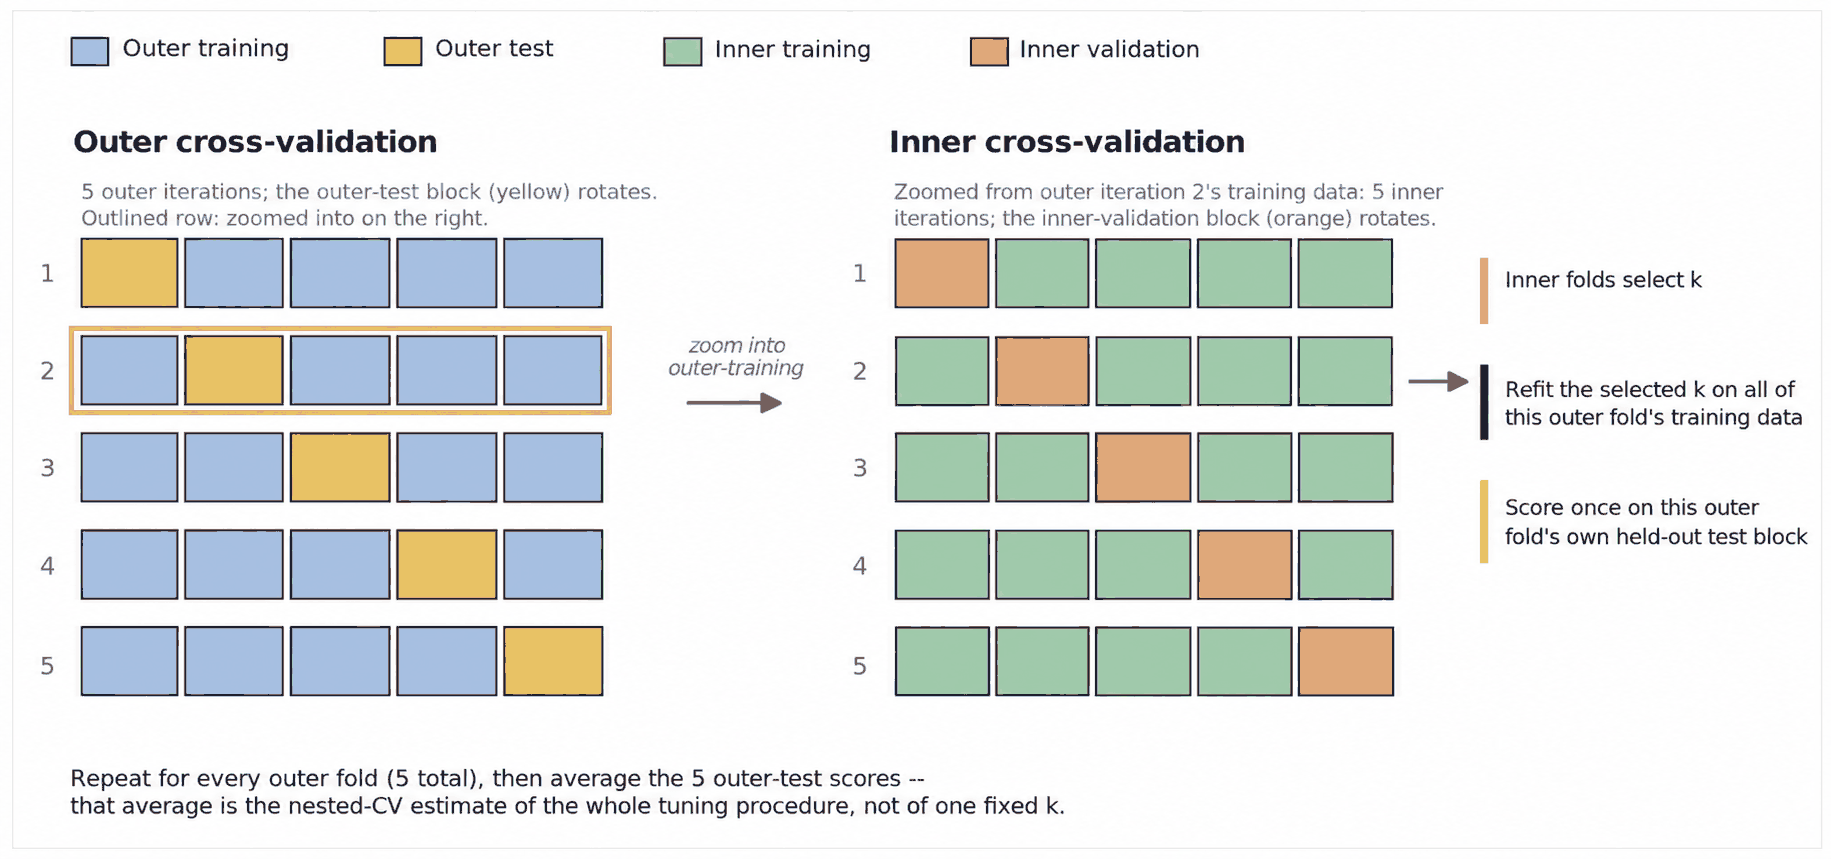

Complete the pipeline below: an outer `KFold` splits the full cohort; for
each outer fold, an inner `GridSearchCV` selects `k` from `NESTED_CANDIDATE_KS`
using only that outer fold's training data; the selected model is then
evaluated once on that outer fold's test data. Because each outer fold's
training data contains different participants, different outer folds
*can* select different `k` -- the inner cross-validation does not have to
agree with itself from fold to fold.


In [ ]:
NESTED_CANDIDATE_KS = [8, 10, 12, 15, 18, 20, 22, 25, 28, 30, 40, 50]
N_OUTER, N_INNER = 5, 5
OUTER_SEED, INNER_SEED = 100, 101

outer_cv = KFold(n_splits=N_OUTER, shuffle=True, random_state=OUTER_SEED)
inner_cv = KFold(n_splits=N_INNER, shuffle=True, random_state=INNER_SEED)

nested_rows = []
for fold_i, (train_idx, test_idx) in enumerate(outer_cv.split(X)):
    X_tr, X_te = X[train_idx], X[test_idx]
    y_tr, y_te = y[train_idx], y[test_idx]

    pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsRegressor())])
    grid = GridSearchCV(
        pipe,
        param_grid={"knn__n_neighbors": NESTED_CANDIDATE_KS},
        scoring="neg_mean_squared_error",
        cv=inner_cv,
    )
    grid.fit(X_tr, y_tr)  # only this outer fold's TRAINING data
    selected_k = grid.best_params_["knn__n_neighbors"]
    pred = grid.predict(X_te)  # the outer TEST fold, evaluated once

    nested_rows.append({
        "outer_fold": fold_i + 1,
        "selected_k": selected_k,
        "outer_test_mse": mean_squared_error(y_te, pred),
        "outer_test_r2": r2_score(y_te, pred),
    })

nested = pd.DataFrame(nested_rows)
nested.round(3)


In [ ]:
# Run this to check your nested cross-validation results.
EXPECTED_NESTED_MEAN_MSE = 33.3552
NESTED_MSE_TOLERANCE = 10.0  # generous: absorbs reasonable implementation differences

if "nested" in globals() and len(nested) > 0:
    if len(nested) != 5:
        print(f"Not quite: found {len(nested)} outer-fold rows; 5-fold outer cross-validation should give exactly 5.")
    elif not set(nested["selected_k"]).issubset(set(NESTED_CANDIDATE_KS)):
        print("Not quite: every selected_k should come from NESTED_CANDIDATE_KS.")
    elif not (nested["outer_test_mse"] >= 0).all():
        print("Not quite: every outer_test_mse should be non-negative.")
    else:
        mean_mse = nested["outer_test_mse"].mean()
        if abs(mean_mse - EXPECTED_NESTED_MEAN_MSE) <= NESTED_MSE_TOLERANCE:
            print(f"Looks good: mean outer-test MSE = {mean_mse:.1f} (expected ~{EXPECTED_NESTED_MEAN_MSE:.1f}).")
        else:
            print(
                f"Your mean outer-test MSE ({mean_mse:.1f}) differs from the expected "
                f"result (~{EXPECTED_NESTED_MEAN_MSE:.1f}). That does not automatically "
                "mean something is wrong -- check that the inner GridSearchCV only ever "
                "sees this outer fold's training data before assuming this is an error."
            )
        print(f"selected k per outer fold: {list(nested['selected_k'])}")
else:
    print("Not complete yet: complete the nested cross-validation pipeline above first.")


With this denser candidate grid, the outer folds may not all agree on
`selected_k` -- different outer folds *can* select different values,
because each outer training set contains different participants. They are
not guaranteed to disagree, only permitted to. The best *inner*
cross-validation score is not reported as a final performance estimate: it
is biased toward whichever candidate happened to look best on the data used
to choose it. The **outer**-test MSE and R², averaged over folds that never
influenced any tuning decision, estimate the performance of the whole
tuning procedure -- not of one fixed model.


> **In your own words, why is it acceptable -- even expected -- for different outer folds to select different values of k, rather than being a sign that something went wrong?**


In [ ]:
show_question("q-inner-loop-data")


In [ ]:
show_question("q-outer-test-mse-meaning")


## In summary

- One train/test split is an honest but single estimate; its exact number
  depends on which participants land in each subset, and that dependence is
  most visible at small sample sizes. Cross-validation evaluates the same
  fixed model across several partitions instead of one.
- scikit-learn's cross-validation scorers report negative MSE so that a
  higher score is always better across every scorer -- negate it back to
  ordinary MSE before interpreting it.
- Nested cross-validation keeps tuning and evaluation separate: an inner
  loop chooses `k`, an outer loop evaluates the whole procedure on data the
  inner loop never saw. Different outer folds can select different `k`
  values, because each has different training data.
- No single validation strategy is always correct -- the right one depends
  on dataset size and on whether the model is being tuned or only evaluated.

Next practice: regularization and feature selection.
